# DriverGuard Lite: Tahap 1–3
Dataset: Driver Monitoring System (Roboflow Universe, CC BY 4.0)

**Sebelum mulai:** Runtime → Change runtime type → **T4 GPU**. Simpan API key Roboflow di menu 🔑 *Secrets* (kiri) dengan nama `ROBOFLOW_API_KEY` dan aktifkan *Notebook access*. Jangan tulis API key langsung di notebook.

## 0. Setup

In [14]:
!nvidia-smi
!pip install -q ultralytics roboflow

Sun Oct 18 10:12:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P0             27W /   70W |    1139MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [15]:
# Simpan hasil training ke Google Drive supaya tidak hilang kalau Colab terputus
from google.colab import drive
drive.mount('/content/drive')
SAVE_DIR = '/content/drive/MyDrive/driverguard'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Download dataset
Cek nomor versi terbaru di tab **Dataset** di halaman Roboflow, lalu sesuaikan `VERSION`.

In [16]:
from google.colab import userdata
from roboflow import Roboflow

VERSION = 11  # ganti sesuai versi dataset yang kamu pilih
rf = Roboflow(api_key=userdata.get('ROBOFLOW_API_KEY'))
project = rf.workspace('driver-monitoring-system-woxvc').project('driver-monitoring-system-v0mei')
dataset = project.version(VERSION).download('yolov11')
DATA = f'{dataset.location}/data.yaml'
print(DATA)
!cat {DATA}

loading Roboflow workspace...
loading Roboflow project...
/content/Driver-Monitoring-system-11/data.yaml
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 8
names: ['Distracted', 'Drinking', 'Drowsy', 'Eating', 'PhoneUse', 'SafeDriving', 'Seatbelt', 'Smoking']

roboflow:
  workspace: driver-monitoring-system-woxvc
  project: driver-monitoring-system-v0mei
  version: 11
  license: CC BY 4.0
  url: https://universe.roboflow.com/driver-monitoring-system-woxvc/driver-monitoring-system-v0mei/dataset/11

## 2. Cek dataset
Tujuannya: tahu jumlah gambar per split, jumlah box per kelas (apakah seimbang?), dan bentuk box-nya seperti apa.

train :  29064 gambar | Distracted=1725, Drinking=1779, Drowsy=4539, Eating=1020, PhoneUse=6195, SafeDriving=24996, Seatbelt=8841, Smoking=8421
valid :   2053 gambar | Distracted=126, Drinking=140, Drowsy=319, Eating=70, PhoneUse=403, SafeDriving=1739, Seatbelt=603, Smoking=655
test  :   1952 gambar | Distracted=118, Drinking=117, Drowsy=284, Eating=82, PhoneUse=444, SafeDriving=1713, Seatbelt=599, Smoking=554


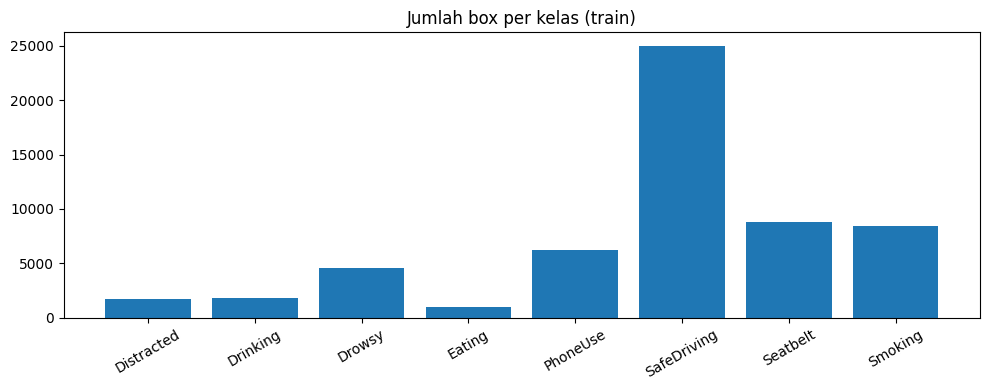

In [8]:
import os, glob, yaml, collections
import matplotlib.pyplot as plt

names = yaml.safe_load(open(DATA))['names']
if isinstance(names, dict): names = [names[k] for k in sorted(names)]

counts = {}
for split in ['train', 'valid', 'test']:
    lbls = glob.glob(f'{dataset.location}/{split}/labels/*.txt')
    c = collections.Counter()
    for f in lbls:
        for line in open(f):
            if line.strip(): c[names[int(line.split()[0])]] += 1
    counts[split] = c
    print(f'{split:6s}: {len(lbls):6d} gambar | ' + ', '.join(f'{k}={v}' for k, v in sorted(c.items())))

plt.figure(figsize=(10, 4))
plt.bar(names, [counts['train'][n] for n in names])
plt.title('Jumlah box per kelas (train)'); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

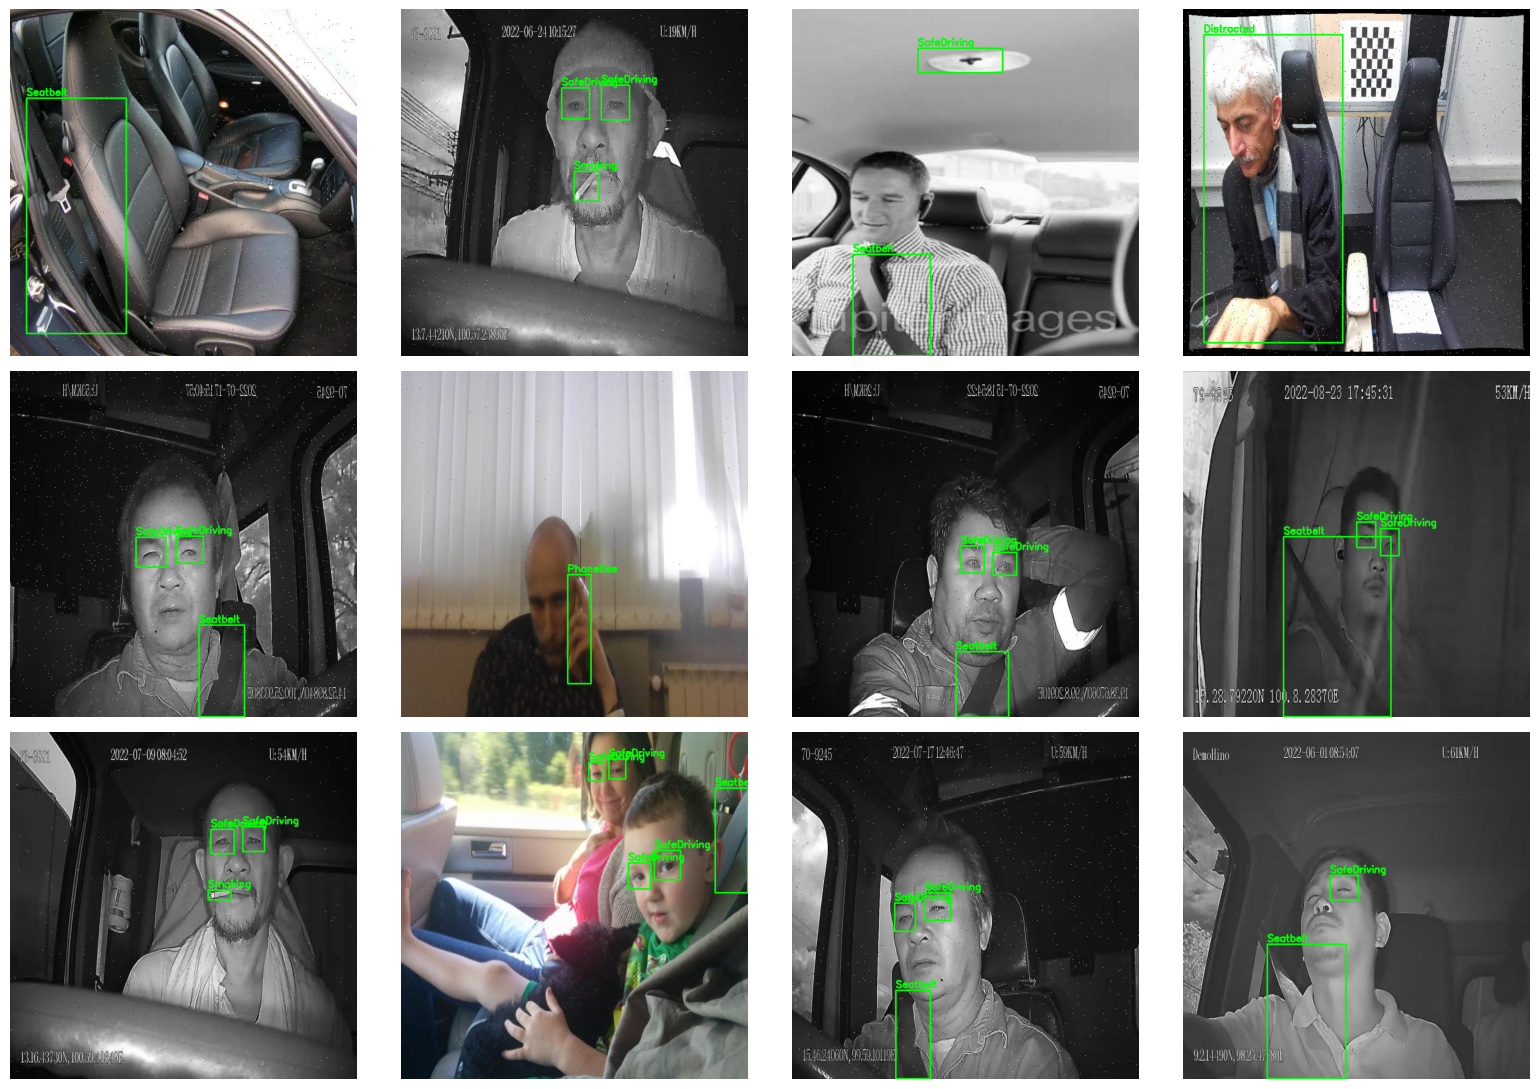

In [9]:
# Lihat 12 sampel acak beserta box-nya
import random, cv2
imgs = random.sample(glob.glob(f'{dataset.location}/train/images/*'), 12)
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, p in zip(axes.flat, imgs):
    im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB); h, w = im.shape[:2]
    lp = p.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
    for line in open(lp) if os.path.exists(lp) else []:
        c, x, y, bw, bh = map(float, line.split()[:5])
        x1, y1, x2, y2 = int((x-bw/2)*w), int((y-bh/2)*h), int((x+bw/2)*w), int((y+bh/2)*h)
        cv2.rectangle(im, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(im, names[int(c)], (x1, max(15, y1-5)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    ax.imshow(im); ax.axis('off')
plt.tight_layout(); plt.show()

**Catat di README:** kelas mana yang jumlahnya sedikit, dan apakah ada label yang terlihat salah. Ini bahan *error analysis* nanti.

## 3. Training
Mulai dari model *nano* (paling ringan, cocok untuk CPU laptop). `patience` menghentikan training otomatis kalau validasi tidak membaik.

In [12]:
from ultralytics import YOLO
model = YOLO('yolo11n.pt')  # pretrained COCO -> transfer learning
model.train(data=DATA, epochs=30, imgsz=640, batch=16, patience=10,
            project=SAVE_DIR, name='v11_run1', exist_ok=True)

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Driver-Monitoring-system-11/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v11_run1, nbs=64, nms=None, opset=None, opti

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bea7956a820>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,

In [ ]:
  model = YOLO(f'{SAVE_DIR}/v11_run1/weights/last.pt')
  model.train(resume=True)

## 4. Evaluasi di test set

In [13]:
best = YOLO(f'{SAVE_DIR}/v11_run1/weights/best.pt')
metrics = best.val(data=DATA, split='test')
print('mAP@0.5     :', round(metrics.box.map50, 3))
print('mAP@0.5:0.95:', round(metrics.box.map, 3))
for i, n in enumerate(names):
    print(f'{n:12s} AP50 = {metrics.box.ap50[i]:.3f}')

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,752 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 18.7±9.0 MB/s, size: 37.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/Driver-Monitoring-system-11/test/labels... 1952 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1952/1952 926.5it/s 2.1s
val: New cache created: /content/Driver-Monitoring-system-11/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 122/122 6.3it/s 19.2s
                   all       1952       3911      0.912      0.891       0.93      0.709
            Distracted        116        118      0.967      0.932      0.975      0.855
              Drinking        116        117      0.852      0.

In [17]:
import os, shutil
from ultralytics import YOLO
W = f'{SAVE_DIR}/v11_run1/weights'
OUT = '/content/export'; os.makedirs(OUT, exist_ok=True)

for name, kw in [('fp32', {}), ('fp16', {'half': True}), ('int8', {'int8': True, 'data': DATA})]:
    path = YOLO(f'{W}/best.pt').export(format='openvino', imgsz=640, **kw)
    shutil.move(path, f'{OUT}/best_{name}_openvino_model')
    print('Selesai:', name)

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,598,752 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/driverguard/v11_run1/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 12, 8400) (5.3 MB)
requirements: Ultralytics requirement ['openvino>=2024.0.0'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 3 packages in 324ms
Prepared 2 packages in 2.68s
Installed 2 packages in 68ms
 + openvino==2026.4.1
 + openvino-telemetry==2025.2.0

requirements: AutoUpdate success ✅ 3.4s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


OpenVINO: starting export with openvino 2026.4.1-22982-e213a147257-releases/2026/4...
OpenVINO: export success ✅ 

Output()

Output()

OpenVINO: export success ✅ 493.4s, saved as '/content/drive/MyDrive/driverguard/v11_run1/weights/best_int8_openvino_model/' (3.2 MB)

Export complete (493.7s)
Results saved to /content/drive/MyDrive/driverguard/v11_run1/weights/best_int8_openvino_model
Predict:         yolo predict task=detect model=/content/drive/MyDrive/driverguard/v11_run1/weights/best_int8_openvino_model/ imgsz=640 
Validate:        yolo val task=detect model=/content/drive/MyDrive/driverguard/v11_run1/weights/best_int8_openvino_model/ imgsz=640 data=/content/Driver-Monitoring-system-11/data.yaml 
Visualize:       https://netron.app
Selesai: int8


In [19]:
for name in ['fp32', 'fp16', 'int8']:
    r = YOLO(f'{OUT}/best_{name}_openvino_model', task='detect').val(
        data=DATA, split='test', imgsz=640, batch=1, verbose=False)
    print(f'{name}: mAP50={r.box.map50:.3f}  mAP50-95={r.box.map:.3f}  Drowsy AP50={r.box.ap50[2]:.3f}')

!cd /content/export && zip -qr openvino_models.zip best_*_openvino_model
from google.colab import files; files.download('/content/export/openvino_models.zip')

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Loading /content/export/best_fp32_openvino_model for OpenVINO inference...
Using OpenVINO LATENCY mode for batch=1 inference on CPU...
Setting batch=1 input of shape (1, 3, 640, 640)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 809.2±394.4 MB/s, size: 33.9 KB)
val: Scanning /content/Driver-Monitoring-system-11/test/labels.cache... 1952 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1952/1952 454.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1952/1952 10.7it/s 3:02
                   all       1952       3911      0.913      0.888      0.927      0.704
Speed: 1.6ms preprocess, 84.0ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/runs/detect/val-5
fp32: mAP50=0.927  mAP50-95=0.704  Drowsy AP50=0.875
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Loading /c

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

File `best.pt` ada di Google Drive: `MyDrive/driverguard/v1/weights/best.pt`. Unduh file itu ke laptop untuk tahap 4 (program webcam).